# 5. AUTO on normal forms

AUTO on three normal forms whose bifurcation diagrams are known in closed form:

```text
  1. supercritical pitchfork   x' = mu x - x^3
         equilibria x = 0 and x = +-sqrt(mu)                         [derivation]
  2. supercritical Hopf        r' = mu r - r^3          (in x, y)
         cycle amplitude sqrt(mu), period 2 pi                       [derivation]
  3. subcritical Hopf          r' = mu r + r^3 - r^5
         cycle amplitude^2 = (1 +- sqrt(1 + 4 mu)) / 2,
         fold of cycles at mu = -1/4                                 [derivation]
```

Shows: starting AUTO from a steady state, AUTO's automatic branch switching at
a branch point, continuing periodic orbits from a Hopf point, and checking
the results against the formulas.  The script version writes auto_normal_forms.png.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pyxpp

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
plt.close(fig)  # drawn into below, shown at the end

## 1. pitchfork

In [2]:
pf = pyxpp.load(text="""
x'=mu*x-x^3
par mu=-1
init x=0
@ total=50
done
""")
pf.run()
pf.run_last()  # AUTO must start on (or very near) an equilibrium

# With XPP's default AUTO settings, AUTO switches branches at a branch point
# by itself, so this one run returns the trivial branch AND both nontrivial
# branches.
br = pf.auto.run("mu", start="steady", ds=0.01, dsmax=0.05, parmin=-1, parmax=1, nmax=200)
print("pitchfork:", br)
bp = br.special("BP")[0]
print(f"  branch point at mu = {bp.x:.2e} (exact 0)")

for b in br.branches():
    mu = np.array([p.x for p in b])
    x = np.array([p.u0["x"] for p in b])
    st = np.array([p.stable for p in b])
    # stability-coloured: red = stable, black = unstable (XPP colours)
    axs[0].scatter(mu, x, s=6, c=np.where(st, "red", "black"))
    if abs(x).max() > 0.1:  # a nontrivial branch: compare with +-sqrt(mu)
        # skip the first step off the branch point, where sqrt is vertical
        sel = mu > 0.01
        err = np.max(np.abs(np.abs(x[sel]) - np.sqrt(mu[sel])))
        print(f"  branch {b[0].branch}: max |x| - sqrt(mu) error = {err:.1e}")
mu = np.linspace(0, 1, 100)
axs[0].plot(mu, np.sqrt(mu), "C0--", lw=1, label=r"$\pm\sqrt{\mu}$")
axs[0].plot(mu, -np.sqrt(mu), "C0--", lw=1)
axs[0].set(title="pitchfork", xlabel=r"$\mu$", ylabel="x")
axs[0].legend()

pitchfork: <Diagram 111 points, labels 1:EP 2:BP 3:EP 4:EP 5:EP>
  branch point at mu = -3.00e-09 (exact 0)
  branch 2: max |x| - sqrt(mu) error = 2.7e-08
  branch 2: max |x| - sqrt(mu) error = 2.7e-08


## 2 and 3. Hopf normal forms: one .ode with the cubic sign s and quintic q

In [3]:
def hopf_model(s, q):
    return pyxpp.load(text=f"""
r2=x^2+y^2
x'=mu*x-y+s*x*r2-q*x*r2^2
y'=x+mu*y+s*y*r2-q*y*r2^2
par mu=-1,s={s},q={q}
init x=0,y=0
@ total=50
done
""")


for ax, (s, q, title) in zip(axs[1:], [(-1, 0, "supercritical Hopf"),
                                        (1, 1, "subcritical Hopf")]):
    m = hopf_model(s, q)
    m.run()
    m.run_last()
    eq = m.auto.run("mu", start="steady", ds=0.01, dsmax=0.05, parmin=-1, parmax=1, nmax=200)
    hb = eq.special("HB")[0]
    print(f"{title}: Hopf at mu = {hb.x:.2e} (exact 0)")

    # grab the Hopf point and follow the periodic orbits born there
    po = m.auto.run(grab=hb.label, choice="periodic", dsmax=0.05, nmax=200)
    mu = np.array([p.x for p in po])
    amp = np.array([p.umax["x"] for p in po])     # max of x over the cycle = radius
    per = np.array([p.period for p in po])
    print(f"  period range {per.min():.6f} .. {per.max():.6f} (exact 2 pi = {2 * np.pi:.6f})")

    # equilibria as lines, cycles as circles at max and min of x
    # (filled green = stable, open blue = unstable)
    m.auto.diagram.plot(y="x", ax=ax, label_points=False)
    if s < 0:
        mm = np.linspace(0, 1, 100)
        ax.plot(mm, np.sqrt(mm), "C1--", lw=1, label=r"$\sqrt{\mu}$")
        sel = mu > 0.01
        print(f"  max amplitude error = {np.max(np.abs(amp[sel] - np.sqrt(mu[sel]))):.1e}")
    else:
        mm = np.linspace(-0.25, 1, 200)
        ax.plot(mm, np.sqrt((1 + np.sqrt(1 + 4 * mm)) / 2), "C1--", lw=1, label="exact")
        mm = np.linspace(-0.25, 0, 100)
        ax.plot(mm, np.sqrt((1 - np.sqrt(1 + 4 * mm)) / 2), "C1--", lw=1)
        fold = po.special("LP")[0]
        print(f"  fold of cycles at mu = {fold.x:.6f} (exact -0.25)")
    ax.set(title=title, xlabel=r"$\mu$", ylabel="x (max/min over cycle)")
    ax.legend(loc="upper left")

fig.tight_layout()

supercritical Hopf: Hopf at mu = -3.00e-09 (exact 0)


  period range 6.283185 .. 6.283185 (exact 2 pi = 6.283185)
  max amplitude error = 3.3e-04


subcritical Hopf: Hopf at mu = -3.00e-09 (exact 0)


  period range 6.283185 .. 6.283185 (exact 2 pi = 6.283185)
  fold of cycles at mu = -0.250000 (exact -0.25)


## The figure

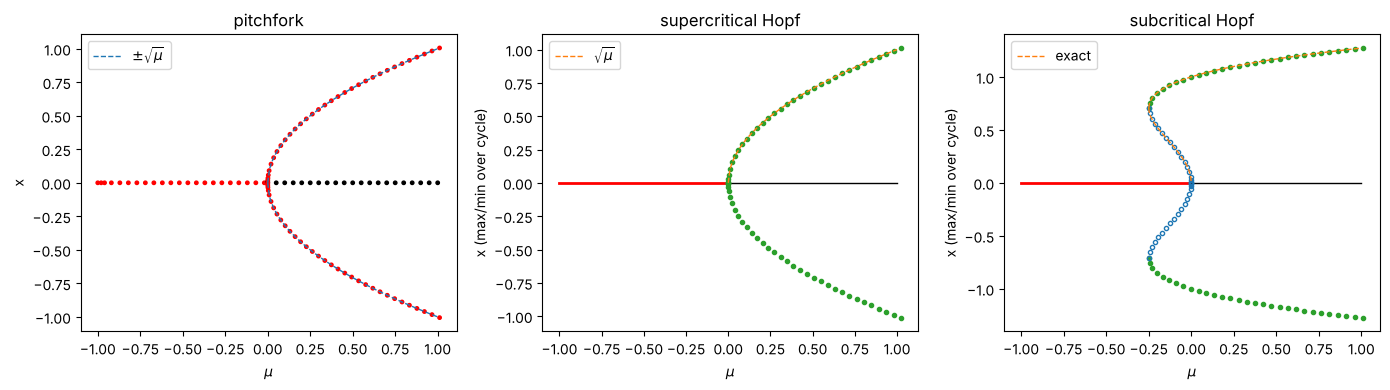

In [4]:
fig